# SmartHire: Resume Category Classifier

In [10]:
# --- Setup: run this first ---
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # make src/ importable

%load_ext autoreload
%autoreload 2

import pandas as pd
from src import config

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from src.features.text_features import build_tfidf

resumes = pd.read_csv(config.RESUMES_CLEAN)
X, y = resumes["Resume"], resumes["Category"]
print(len(X), "resumes |", y.nunique(), "classes")

166 resumes | 25 classes


In [12]:
models = {
    "Naive Bayes":         MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=2000, C=10),
    "Linear SVM":          LinearSVC(C=1.0),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=config.RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=config.RANDOM_STATE)

rows = []
for name, model in models.items():
    pipe = make_pipeline(build_tfidf(), model)
    scores = cross_validate(pipe, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append({
        "model": name,
        "accuracy": scores["test_accuracy"].mean(),
        "accuracy_std": scores["test_accuracy"].std(),
        "f1_macro": scores["test_f1_macro"].mean(),
    })

results = pd.DataFrame(rows).sort_values("f1_macro", ascending=False).round(3)
results

,model,accuracy,accuracy_std,f1_macro
2,Linear SVM,0.886,0.033,0.846
1,Logistic Regression,0.850,0.060,0.792
0,Naive Bayes,0.795,0.035,0.729
3,Random Forest,0.772,0.067,0.719


## Leakage Experiment

In [13]:
from sklearn.model_selection import train_test_split

raw = pd.read_csv(config.RESUME_RAW)
Xtr, Xte, ytr, yte = train_test_split(
    raw["Resume"], raw["Category"], test_size=0.2,
    random_state=config.RANDOM_STATE, stratify=raw["Category"])

leaky = make_pipeline(build_tfidf(), LinearSVC()).fit(Xtr, ytr)

print(f"{Xte.isin(Xtr).mean():.0%} of test resumes ALSO appear in the training set")
print("Accuracy WITH duplicates (leaky):  ", round(leaky.score(Xte, yte), 3))
print("Accuracy WITHOUT duplicates (CV):  ", results.loc[results.model == "Linear SVM", "accuracy"].item())

99% of test resumes ALSO appear in the training set
Accuracy WITH duplicates (leaky):   1.0
Accuracy WITHOUT duplicates (CV):   0.886


## Final Model Evaluation

                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00        10
                     Arts       1.00      1.00      1.00         6
       Automation Testing       0.86      0.86      0.86         7
               Blockchain       1.00      0.60      0.75         5
         Business Analyst       0.75      1.00      0.86         6
           Civil Engineer       1.00      1.00      1.00         6
             Data Science       0.82      0.90      0.86        10
                 Database       0.83      0.91      0.87        11
          DevOps Engineer       1.00      0.71      0.83         7
         DotNet Developer       0.78      1.00      0.88         7
            ETL Developer       0.83      1.00      0.91         5
   Electrical Engineering       0.62      1.00      0.77         5
                       HR       1.00      1.00      1.00        10
                   Hadoop       1.00      1.00      1.00     

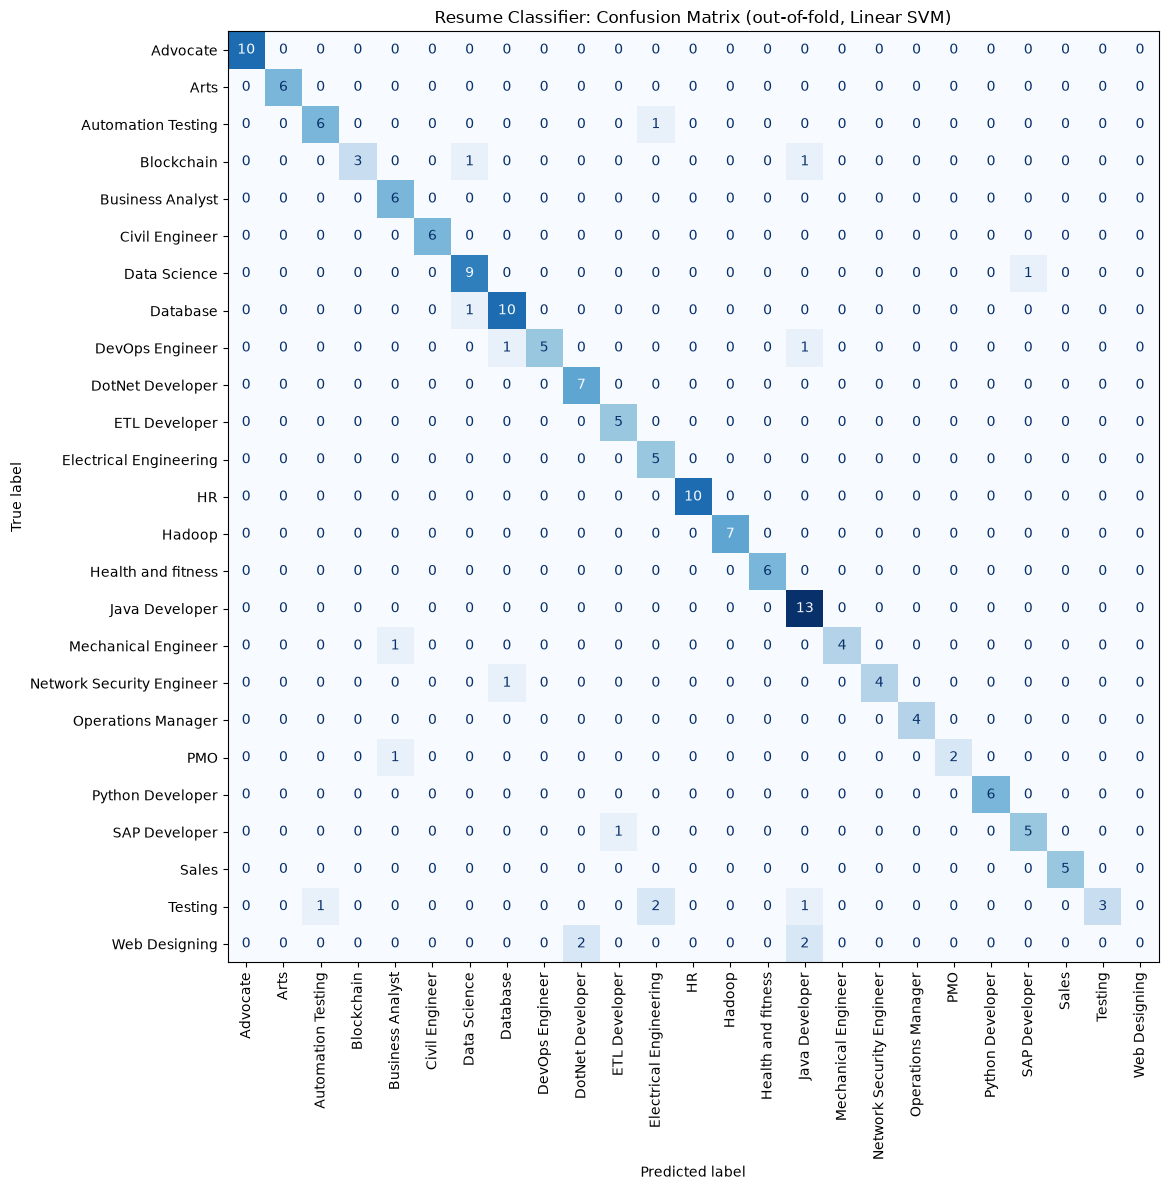

In [14]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best = make_pipeline(build_tfidf(), LinearSVC(C=1.0))
y_pred = cross_val_predict(best, X, y, cv=cv)   # every resume predicted by a model that never saw it

print(classification_report(y, y_pred, zero_division=0))

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(y, y_pred, ax=ax, xticks_rotation=90,
                                        cmap="Blues", colorbar=False)
ax.set_title("Resume Classifier: Confusion Matrix (out-of-fold, Linear SVM)")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "02_confusion_matrix.png", dpi=150)
plt.show()

In [15]:
from src.models.classifier import train_and_save, predict_top_k

clf = train_and_save(X, y)
sample = ("Skilled in Python, pandas, scikit-learn, machine learning, deep learning, "
          "NLP and statistics. Built predictive models and dashboards in Tableau.")
predict_top_k(clf, sample)

[('Data Science', 0.285)]

In [16]:
for cat in ["Python Developer", "HR", "Web Designing"]:
    text = resumes.loc[resumes["Category"] == cat, "Resume"].iloc[0]
    print(f"{cat:18} -> {predict_top_k(clf, text)}")

Python Developer   -> [('Python Developer', 0.474)]
HR                 -> [('HR', 0.625)]
Web Designing      -> [('Web Designing', 0.401)]


## Conclusions

1. Linear SVM performed best: 88.6% accuracy and 0.844 macro F1 using 3-fold stratified cross-validation.
3. And as per the leakage experiment, i found out that 99% of the test resumes appear on the train resume. 
4. The weakest class is Web designing